# Below Zero: three years, explored

April 2023 – March 2026. Exploratory charts to decide what the piece should focus on. Everything here reads from `data/tidy/` (built by `src/tidy.py` from the raw cache) plus NESO's cached constraint breakdown. Nothing calls an API.

Terms used throughout:
- **Paid curtailment**: money paid to wind farms for accepted bids to reduce output (positive cash to the unit).
- **System action**: the acceptance carries Elexon's `soFlag`, our stand-in for "taken because of a grid constraint". Not an exact match: see the README.
- **SHET / SPT / NGET**: the transmission owner a wind farm connects to, i.e. north Scotland / south Scotland / England & Wales.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from plotnine import *

sys.path.append(str(Path("..") / "src"))
from fetch import CONSTRAINT_BREAKDOWN_IDS, bmunits_cache_path, constraint_breakdown_cache_path
from parse import parse_bmunits

DATA = Path("..") / "data"
FIG_DIR = Path("..") / "figures" / "explore"
FIG_DIR.mkdir(parents=True, exist_ok=True)

ELEXON = "Source: Elexon BMRS (EBOCF, BOAV, BOALF, MID)."
NESO = "Source: NESO constraint breakdown; Elexon BMRS."
REGIONS = {"SHET": "North Scotland (SHET)", "SPT": "South Scotland (SPT)", "NGET": "England & Wales (NGET)"}
# One hue in three lightness steps, north to south: still separable in greyscale
REGION_COLOURS = dict(zip(REGIONS.values(), ["#184f95", "#2a78d6", "#86b6ef"]))


def house_theme(width: float = 9, height: float = 4.8):
    """The same look for every chart: light surface, minimal grid, legend on top."""
    return theme_minimal(base_size=11) + theme(
        figure_size=(width, height),
        legend_position="top",
        panel_grid_minor=element_blank(),
        plot_background=element_rect(fill="#fcfcfb", color="#fcfcfb"),
        plot_caption=element_text(size=8, color="#52514e"),
        plot_subtitle=element_text(color="#52514e"),
    )


def save(fig, name: str):
    fig.save(FIG_DIR / f"{name}.png", dpi=150, verbose=False)
    return fig

In [2]:
half = pd.read_csv(DATA / "tidy" / "halfhourly.csv", parse_dates=["settlement_date", "start_utc"])
half["start_local"] = half["start_utc"].dt.tz_convert("Europe/London")
half["month"] = half["settlement_date"].dt.to_period("M").dt.to_timestamp()

cash_cols = [c for c in half.columns if c.startswith("wind_bid_cash_gbp_")]
vol_cols = [c for c in half.columns if c.startswith("wind_bid_volume_mwh_")]
half["wind_cash"] = half[cash_cols].sum(axis=1)
half["wind_cash_system"] = half[[c for c in cash_cols if c.endswith("_system")]].sum(axis=1)
half["wind_mwh"] = -half[vol_cols].sum(axis=1)              # MWh switched off (positive)
half["wind_mwh_system"] = -half[[c for c in vol_cols if c.endswith("_system")]].sum(axis=1)

# Long form of the wind cash columns: one row per half hour x host TO x flag
wind_long = half.melt(id_vars=["settlement_date", "month", "start_local"], value_vars=cash_cols, value_name="cash_gbp")
wind_long[["host_to", "action"]] = wind_long["variable"].str.extract(r"_gbp_(\w+)_(\w+)$")
wind_long["region"] = wind_long["host_to"].map(REGIONS)

neso = pd.concat([pd.read_csv(constraint_breakdown_cache_path(fy)) for fy in CONSTRAINT_BREAKDOWN_IDS])
neso["month"] = pd.to_datetime(neso["Date"]).dt.to_period("M").dt.to_timestamp()

units = parse_bmunits(bmunits_cache_path())
bmunit_map = pd.read_csv(DATA / "bmunit_map.csv")
by_unit = (pd.read_csv(DATA / "tidy" / "monthly_by_unit.csv")
           .merge(units[["bm_unit", "ng_bm_unit", "name", "fuel_type"]], on="bm_unit", how="left")
           .merge(bmunit_map[["bm_unit", "site", "host_to"]], on="bm_unit", how="left"))

print(f"{len(half):,} half-hours, {half['settlement_date'].nunique()} days")
print(f"Paid curtailment of wind: £{half['wind_cash'].sum() / 1e6:,.0f}m, "
      f"of which system actions £{half['wind_cash_system'].sum() / 1e6:,.0f}m")

52,608 half-hours, 1096 days
Paid curtailment of wind: £1,129m, of which system actions £1,061m


## 1. Chart 1 draft: monthly paid curtailment

Two cuts of the same total: by flag (the planned chart 1) and by where the wind farm is.

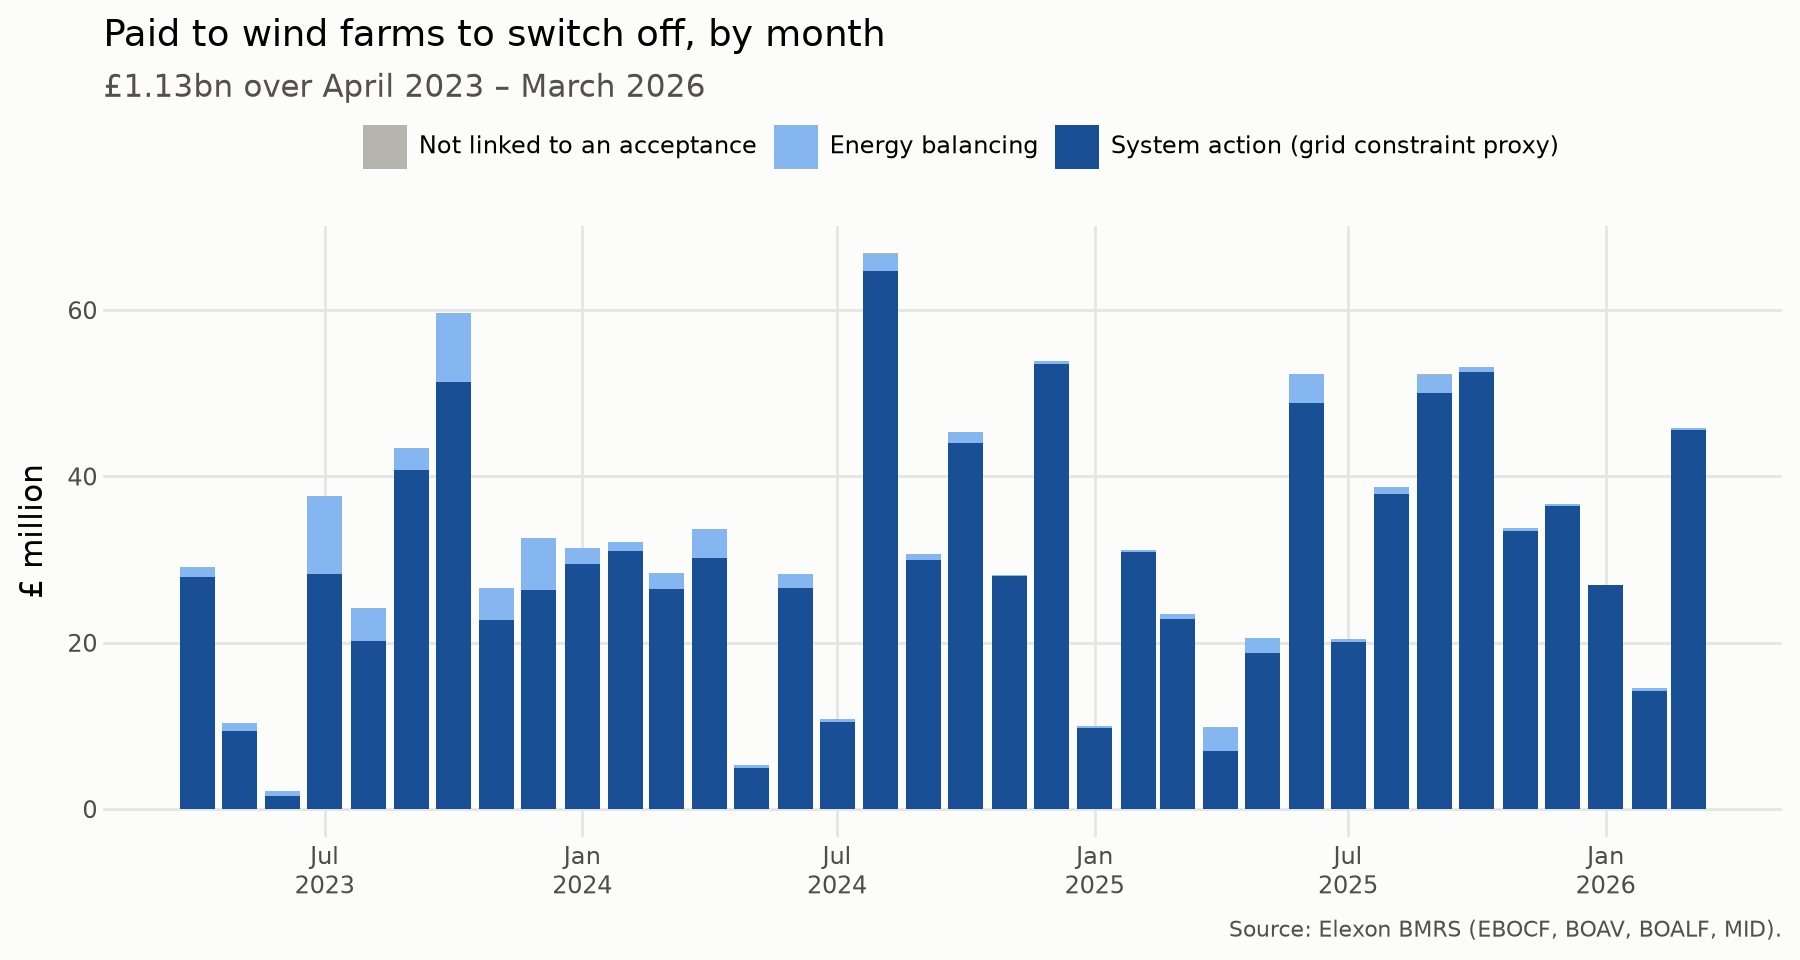

In [3]:
ACTIONS = {"system": "System action (grid constraint proxy)", "energy": "Energy balancing", "unknown": "Not linked to an acceptance"}
by_flag = wind_long.groupby(["month", "action"], as_index=False)["cash_gbp"].sum()
by_flag["action"] = pd.Categorical(by_flag["action"].map(ACTIONS), categories=list(ACTIONS.values())[::-1])

save(
    ggplot(by_flag, aes("month", "cash_gbp / 1e6", fill="action"))
    + geom_col(width=25)
    + scale_fill_manual(values={ACTIONS["system"]: "#184f95", ACTIONS["energy"]: "#86b6ef", ACTIONS["unknown"]: "#b5b4ad"})
    + scale_x_datetime(date_labels="%b\n%Y", date_breaks="6 months")
    + labs(title="Paid to wind farms to switch off, by month",
           subtitle=f"£{half['wind_cash'].sum() / 1e9:.2f}bn over April 2023 – March 2026",
           x="", y="£ million", fill="", caption=ELEXON)
    + house_theme(),
    "01_monthly_curtailment_by_flag",
)

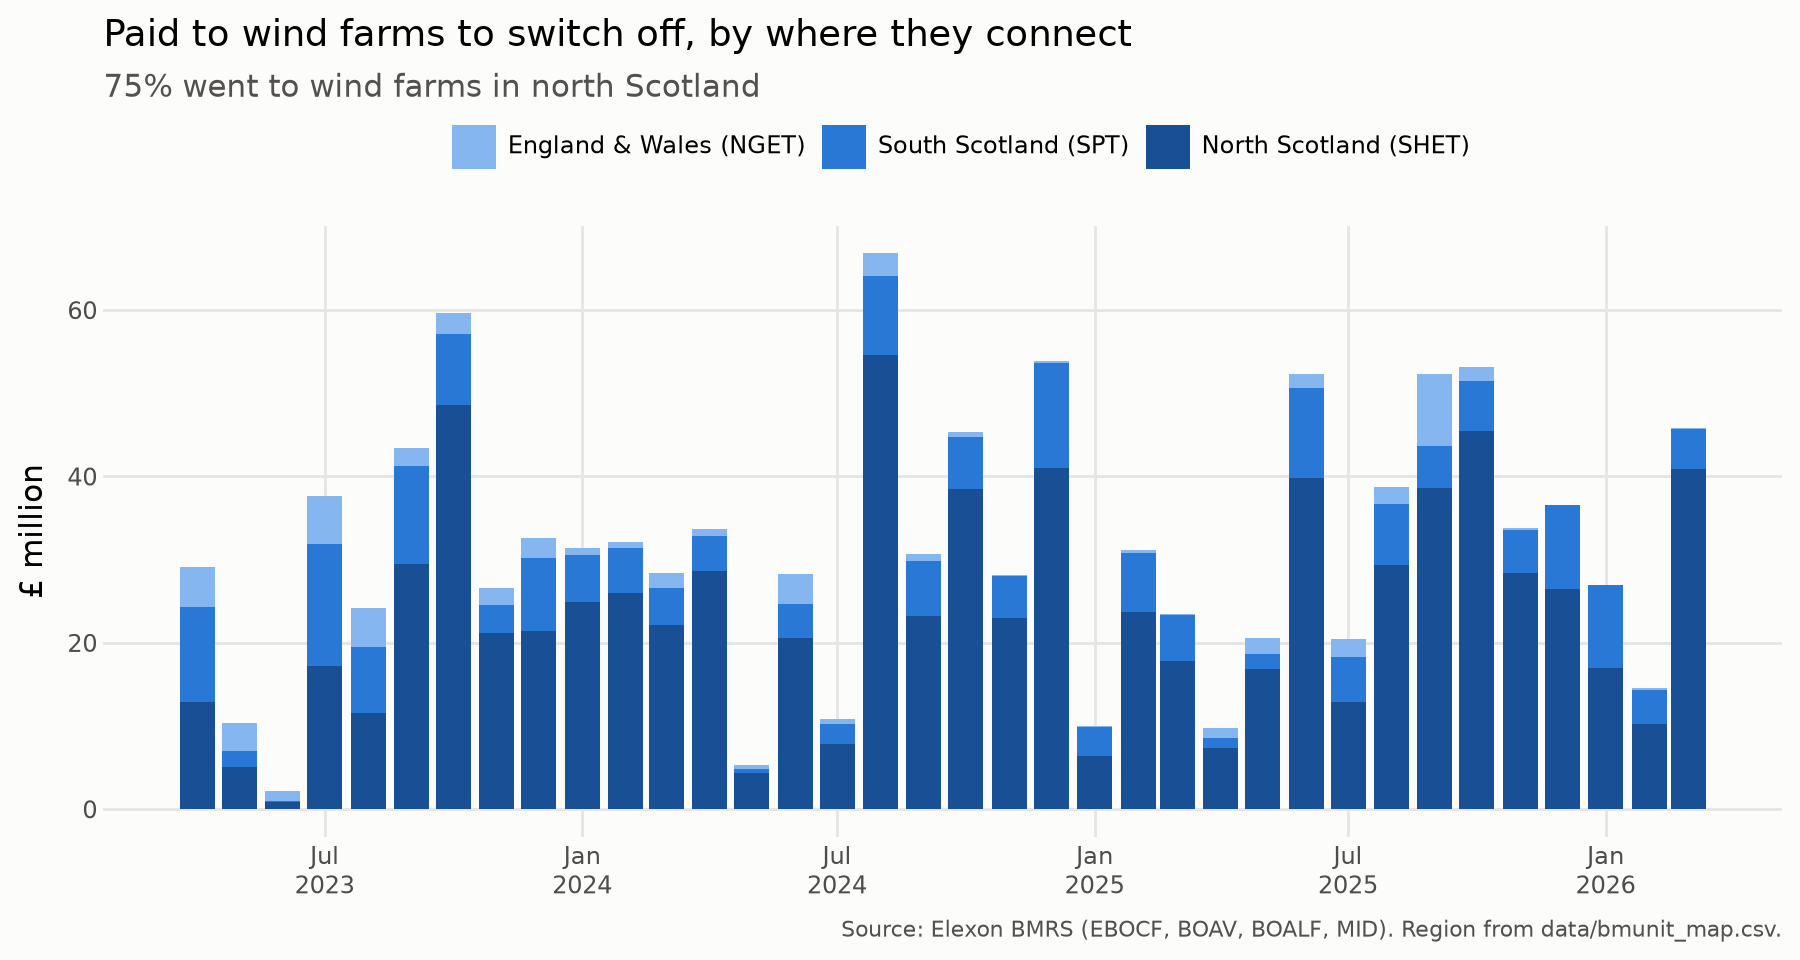

In [4]:
by_region = wind_long.groupby(["month", "region"], as_index=False)["cash_gbp"].sum()
by_region["region"] = pd.Categorical(by_region["region"], categories=list(REGIONS.values())[::-1])
share_north = by_region.loc[by_region["region"] == REGIONS["SHET"], "cash_gbp"].sum() / by_region["cash_gbp"].sum()

save(
    ggplot(by_region, aes("month", "cash_gbp / 1e6", fill="region"))
    + geom_col(width=25)
    + scale_fill_manual(values=REGION_COLOURS)
    + scale_x_datetime(date_labels="%b\n%Y", date_breaks="6 months")
    + labs(title="Paid to wind farms to switch off, by where they connect",
           subtitle=f"{share_north:.0%} went to wind farms in north Scotland",
           x="", y="£ million", fill="", caption=ELEXON + " Region from data/bmunit_map.csv.")
    + house_theme(),
    "02_monthly_curtailment_by_region",
)

## 2. Does the bottom-up build match NESO?

Volume is the cleanest test: our system-flagged wind volume against NESO's published thermal-constraint volume.

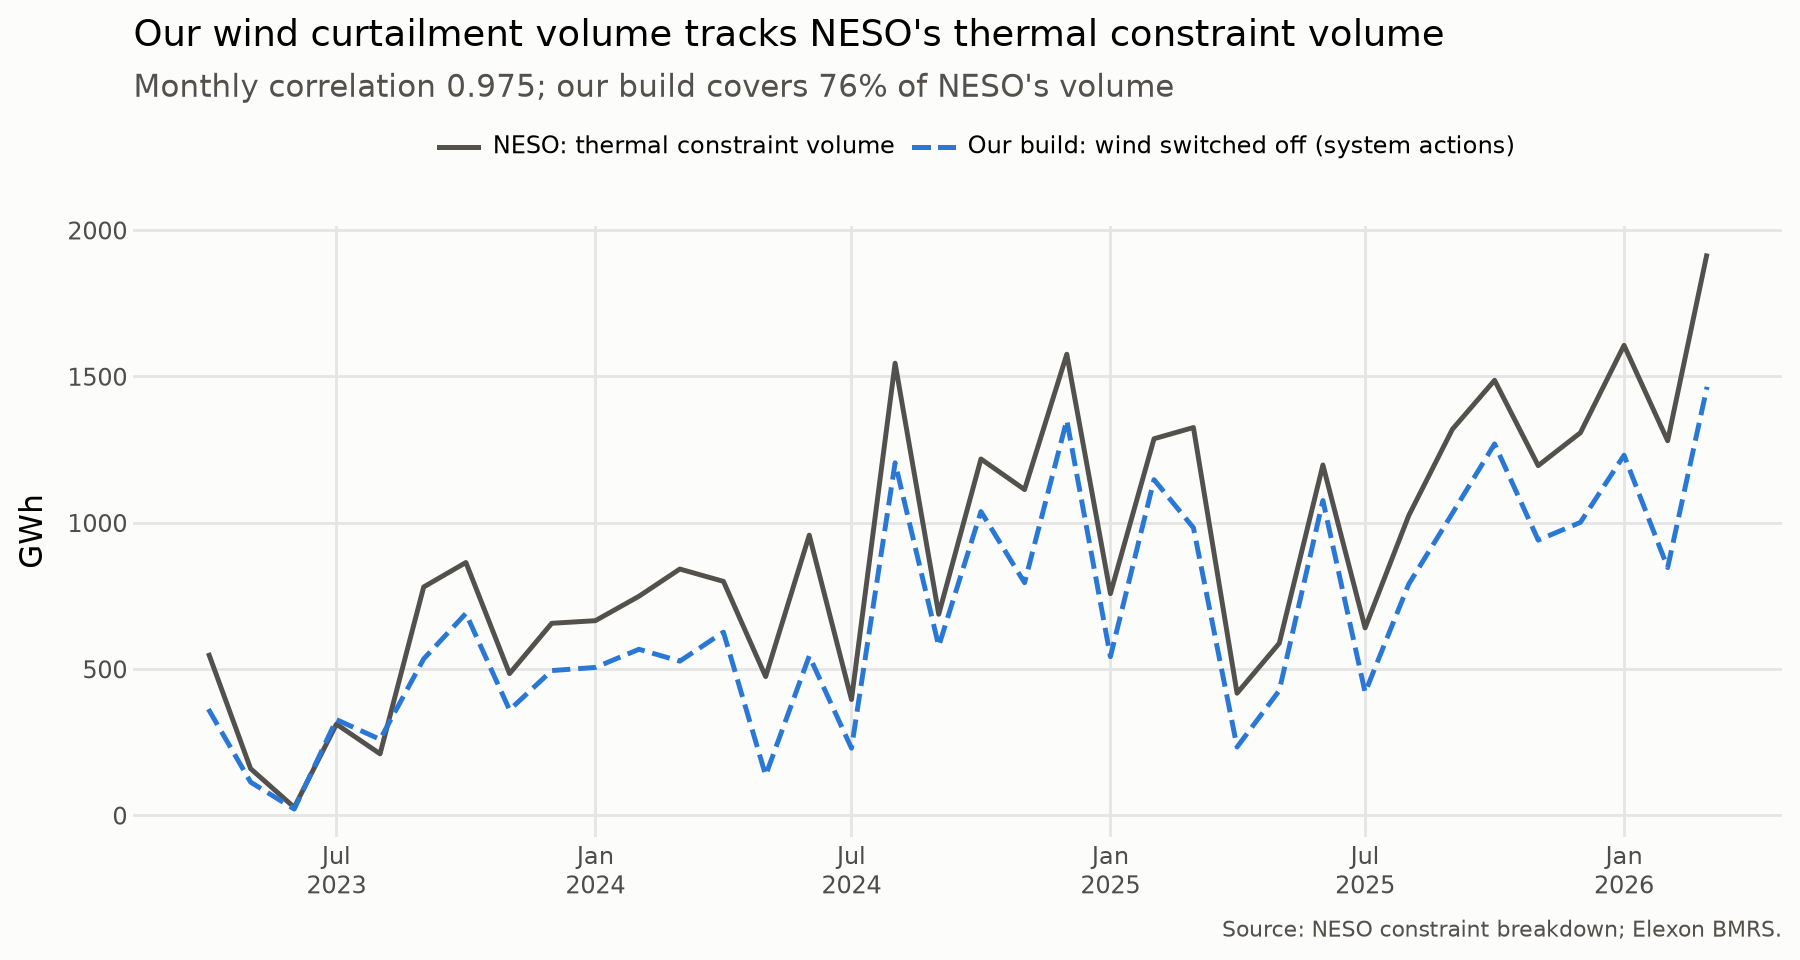

In [5]:
recon = (half.groupby("month")["wind_mwh_system"].sum().to_frame("Our build: wind switched off (system actions)")
         .join(-neso.groupby("month")["Thermal constraints volume"].sum().rename("NESO: thermal constraint volume")))
corr = recon.corr().iloc[0, 1]
ratio = recon.iloc[:, 0].sum() / recon.iloc[:, 1].sum()
recon_long = recon.reset_index().melt(id_vars="month", var_name="series", value_name="mwh")

save(
    ggplot(recon_long, aes("month", "mwh / 1e3", color="series", linetype="series"))
    + geom_line(size=1)
    + scale_color_manual(values=["#52514e", "#2a78d6"])
    + scale_x_datetime(date_labels="%b\n%Y", date_breaks="6 months")
    + labs(title="Our wind curtailment volume tracks NESO's thermal constraint volume",
           subtitle=f"Monthly correlation {corr:.3f}; our build covers {ratio:.0%} of NESO's volume",
           x="", y="GWh", color="", linetype="", caption=NESO)
    + house_theme(),
    "03_reconciliation_volume",
)

## 3. Chart 3 draft: where NESO's thermal constraint cost goes

NESO's published thermal constraint cost, split into the part paid to wind farms to switch off (our bottom-up figure) and everything else, which is mostly paying other generators to increase output elsewhere.

       neso_total  Paid to wind farms to switch off
month                                              
2023        757.0                             228.0
2024       1482.0                             379.0
2025       1831.0                             368.0
2026        635.0                              87.0


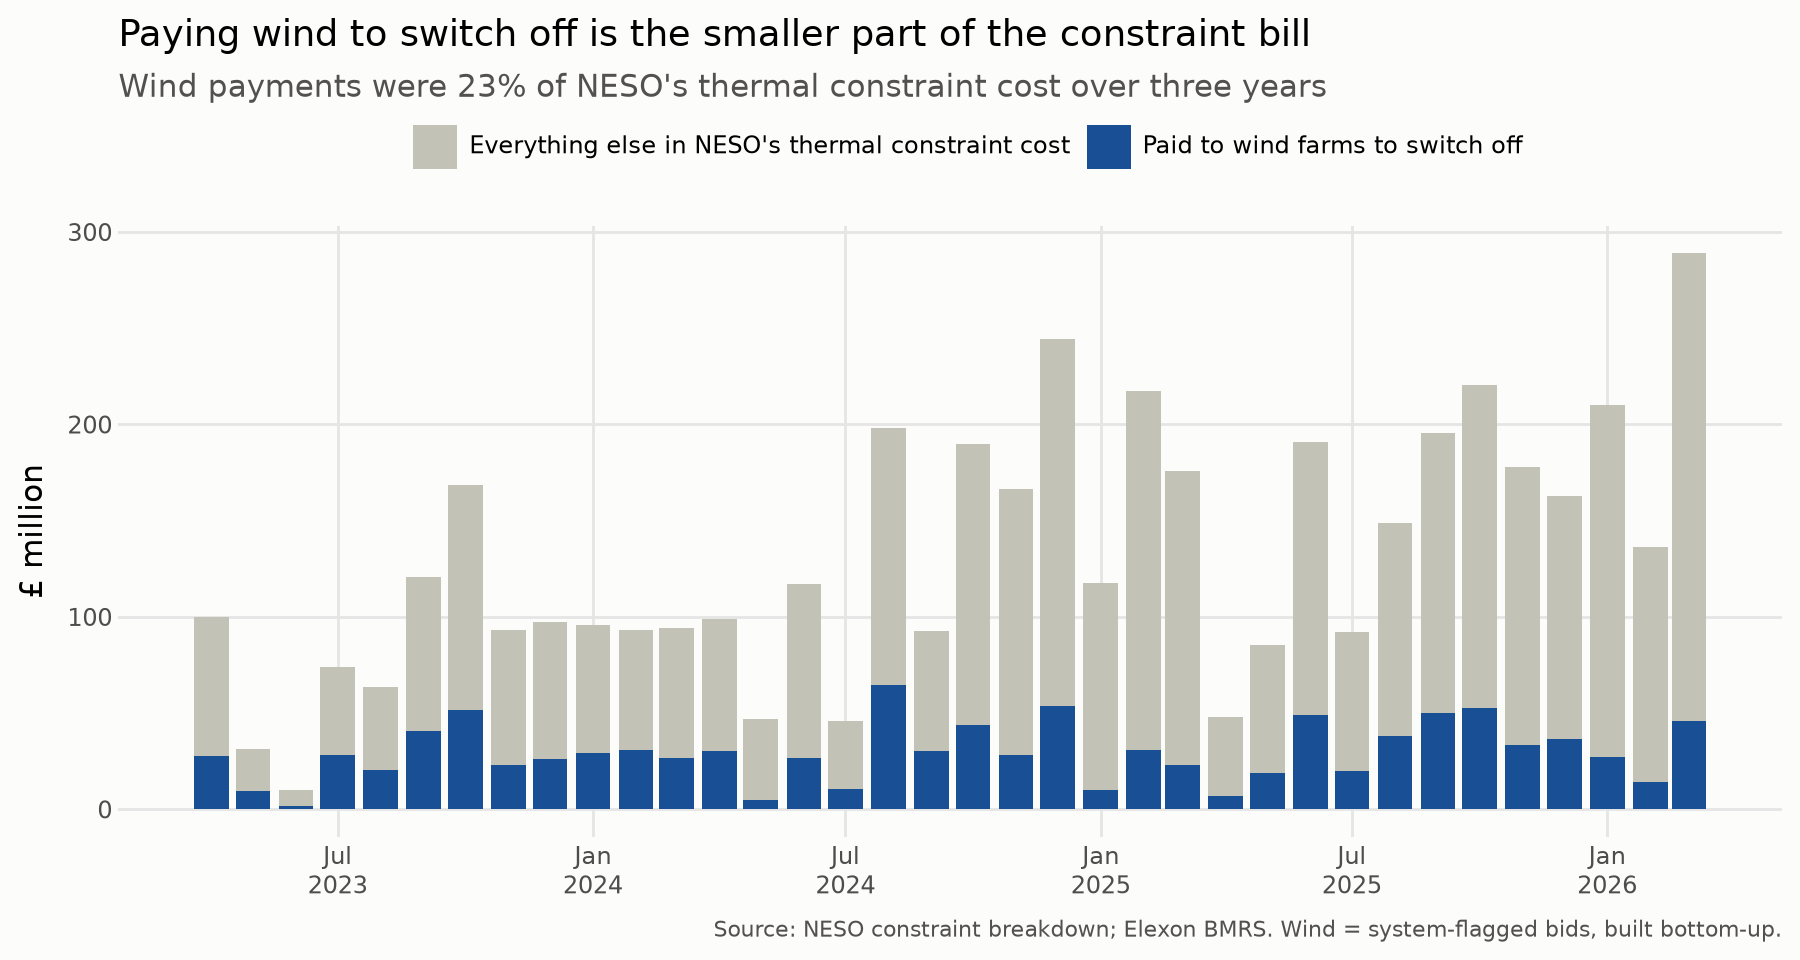

In [6]:
split = (neso.groupby("month")["Thermal constraints cost"].sum().to_frame("neso_total")
         .join(half.groupby("month")["wind_cash_system"].sum()))
split["Everything else in NESO's thermal constraint cost"] = split["neso_total"] - split["wind_cash_system"]
split = split.rename(columns={"wind_cash_system": "Paid to wind farms to switch off"})
split_long = split.drop(columns="neso_total").reset_index().melt(id_vars="month", var_name="part", value_name="gbp")
split_long["part"] = pd.Categorical(split_long["part"], categories=["Everything else in NESO's thermal constraint cost",
                                                                    "Paid to wind farms to switch off"])
wind_share = split["Paid to wind farms to switch off"].sum() / split["neso_total"].sum()
print((split.groupby(split.index.year)[["neso_total", "Paid to wind farms to switch off"]].sum() / 1e6).round(0))

save(
    ggplot(split_long, aes("month", "gbp / 1e6", fill="part"))
    + geom_col(width=25)
    + scale_fill_manual(values={"Paid to wind farms to switch off": "#184f95",
                                "Everything else in NESO's thermal constraint cost": "#c3c2b7"})
    + scale_x_datetime(date_labels="%b\n%Y", date_breaks="6 months")
    + labs(title="Paying wind to switch off is the smaller part of the constraint bill",
           subtitle=f"Wind payments were {wind_share:.0%} of NESO's thermal constraint cost over three years",
           x="", y="£ million", fill="", caption=NESO + " Wind = system-flagged bids, built bottom-up.")
    + house_theme(),
    "04_thermal_cost_split",
)

## 4. When does it happen?

Average paid curtailment per half hour, by local hour of day and month.

Average index by hour of day (1 = that month's average):
hour
0     1.22
1     1.20
2     1.20
3     1.22
4     1.27
5     1.29
6     1.18
7     1.01
8     0.87
9     0.82
10    0.83
11    0.85
12    0.87
13    0.90
14    0.96
15    0.94
16    0.87
17    0.82
18    0.79
19    0.84
20    0.89
21    0.95
22    1.05
23    1.17


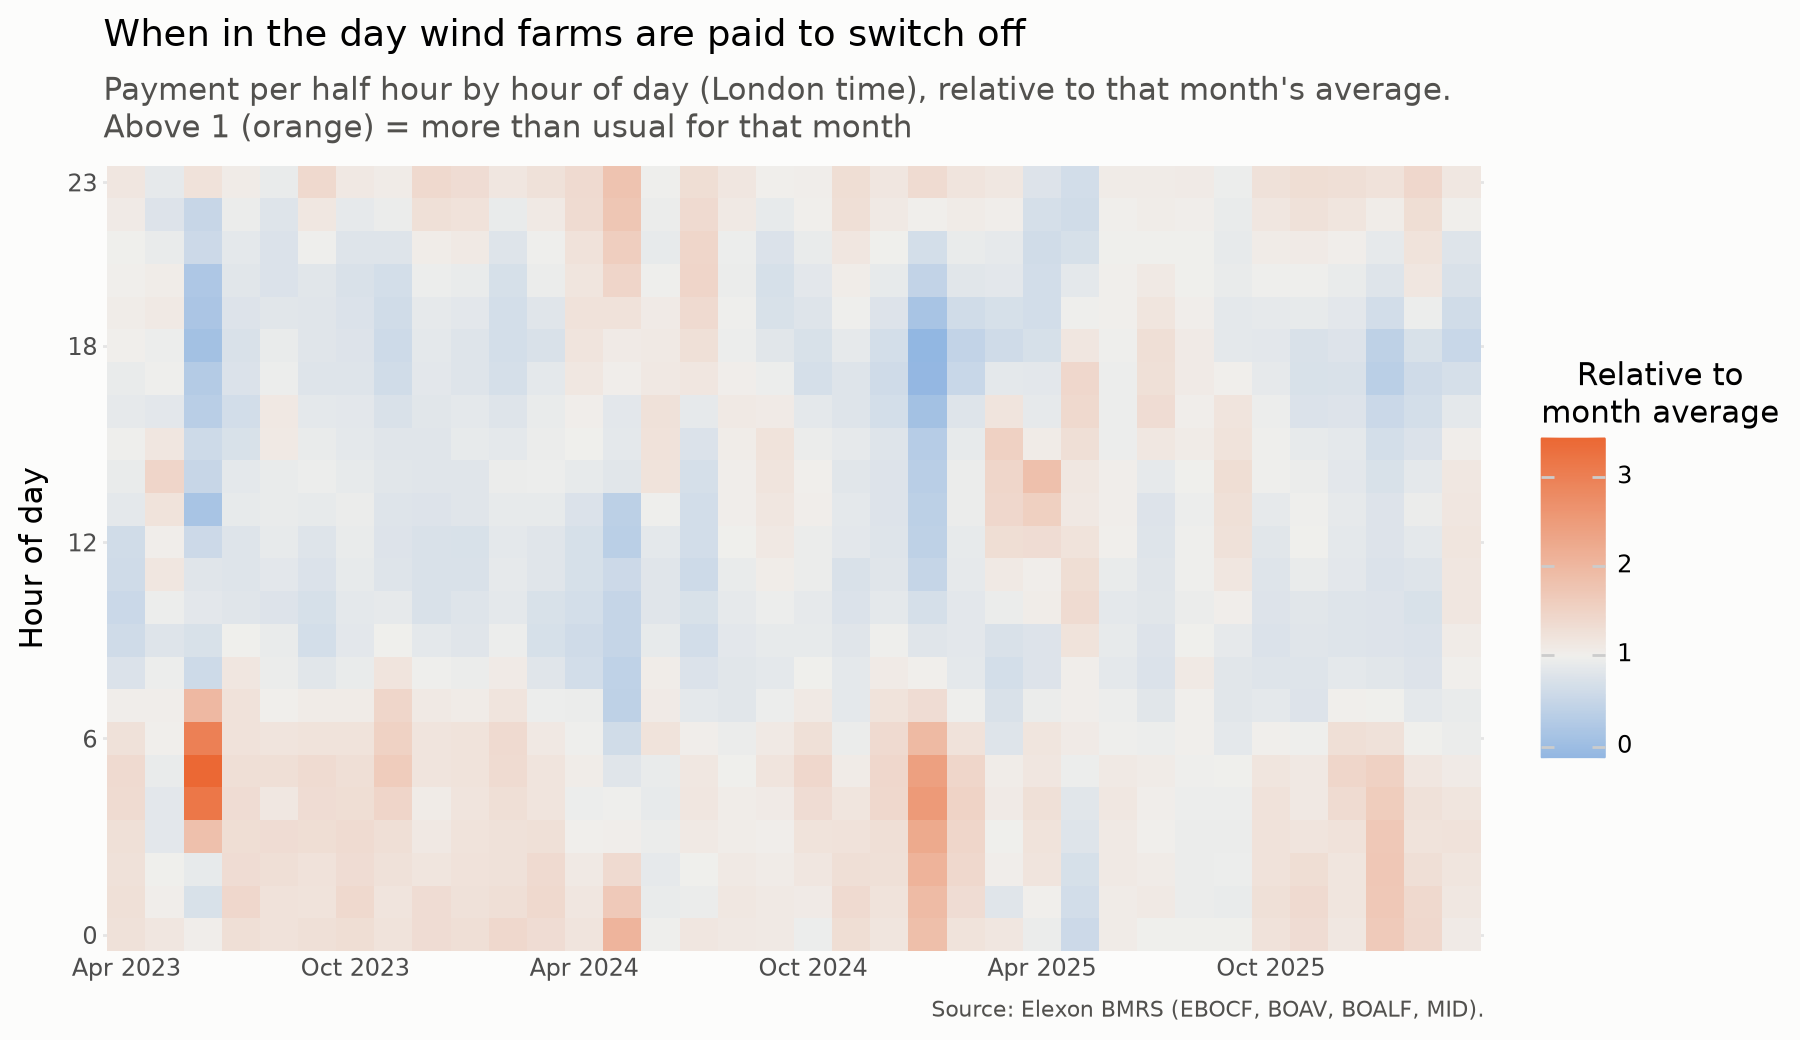

In [7]:
heat = (half.assign(hour=half["start_local"].dt.hour)
        .groupby(["month", "hour"], as_index=False)["wind_cash"].mean())
# Divide by each month's own average, so the daily shape shows despite big month-to-month swings
heat["index"] = heat["wind_cash"] / heat.groupby("month")["wind_cash"].transform("mean")
heat["month_label"] = heat["month"].dt.strftime("%b %Y")
month_order = heat.drop_duplicates("month").sort_values("month")["month_label"].tolist()
heat["month_label"] = pd.Categorical(heat["month_label"], categories=month_order)
by_hour = heat.groupby("hour")["index"].mean()
print("Average index by hour of day (1 = that month's average):")
print(by_hour.round(2).to_string())

save(
    ggplot(heat, aes("month_label", "hour", fill="index"))
    + geom_tile()
    + scale_fill_gradient2(low="#2a78d6", mid="#f0efec", high="#eb6834", midpoint=1,
                           name="Relative to\nmonth average")
    + scale_x_discrete(breaks=month_order[::6])
    + scale_y_continuous(breaks=[0, 6, 12, 18, 23], expand=(0, 0))
    + labs(title="When in the day wind farms are paid to switch off",
           subtitle="Payment per half hour by hour of day (London time), relative to that month's average.\n"
                    "Above 1 (orange) = more than usual for that month",
           x="", y="Hour of day", caption=ELEXON)
    + house_theme(height=5.2) + theme(legend_position="right"),
    "05_heatmap_hour_month",
)

## 5. Negative prices and paid curtailment: same thing or not?

Each half hour grouped by its wholesale price (`MID`). Bars: average paid curtailment in that price band. Labels: how many half hours fall in the band.

      band  mean_cash  half_hours  share_curtailing  negative
     < -20  100139.56         226              0.97      True
-20 to -10   82830.19         288              0.97      True
  -10 to 0   74616.42         883              0.98      True
   0 to 10   76923.43        1117              0.98     False
  10 to 20   72594.61         970              0.98     False
  20 to 40   60848.68        2024              0.95     False
  40 to 60   38374.52        4606              0.74     False
  60 to 80   16825.12       15397              0.52     False
 80 to 100   12748.03       16529              0.49     False
100 to 150    9000.68       10002              0.46     False
     > 150    -197.10         542              0.13     False
Negative-price half hours: 2.7% of all; they carry 10.0% of paid curtailment


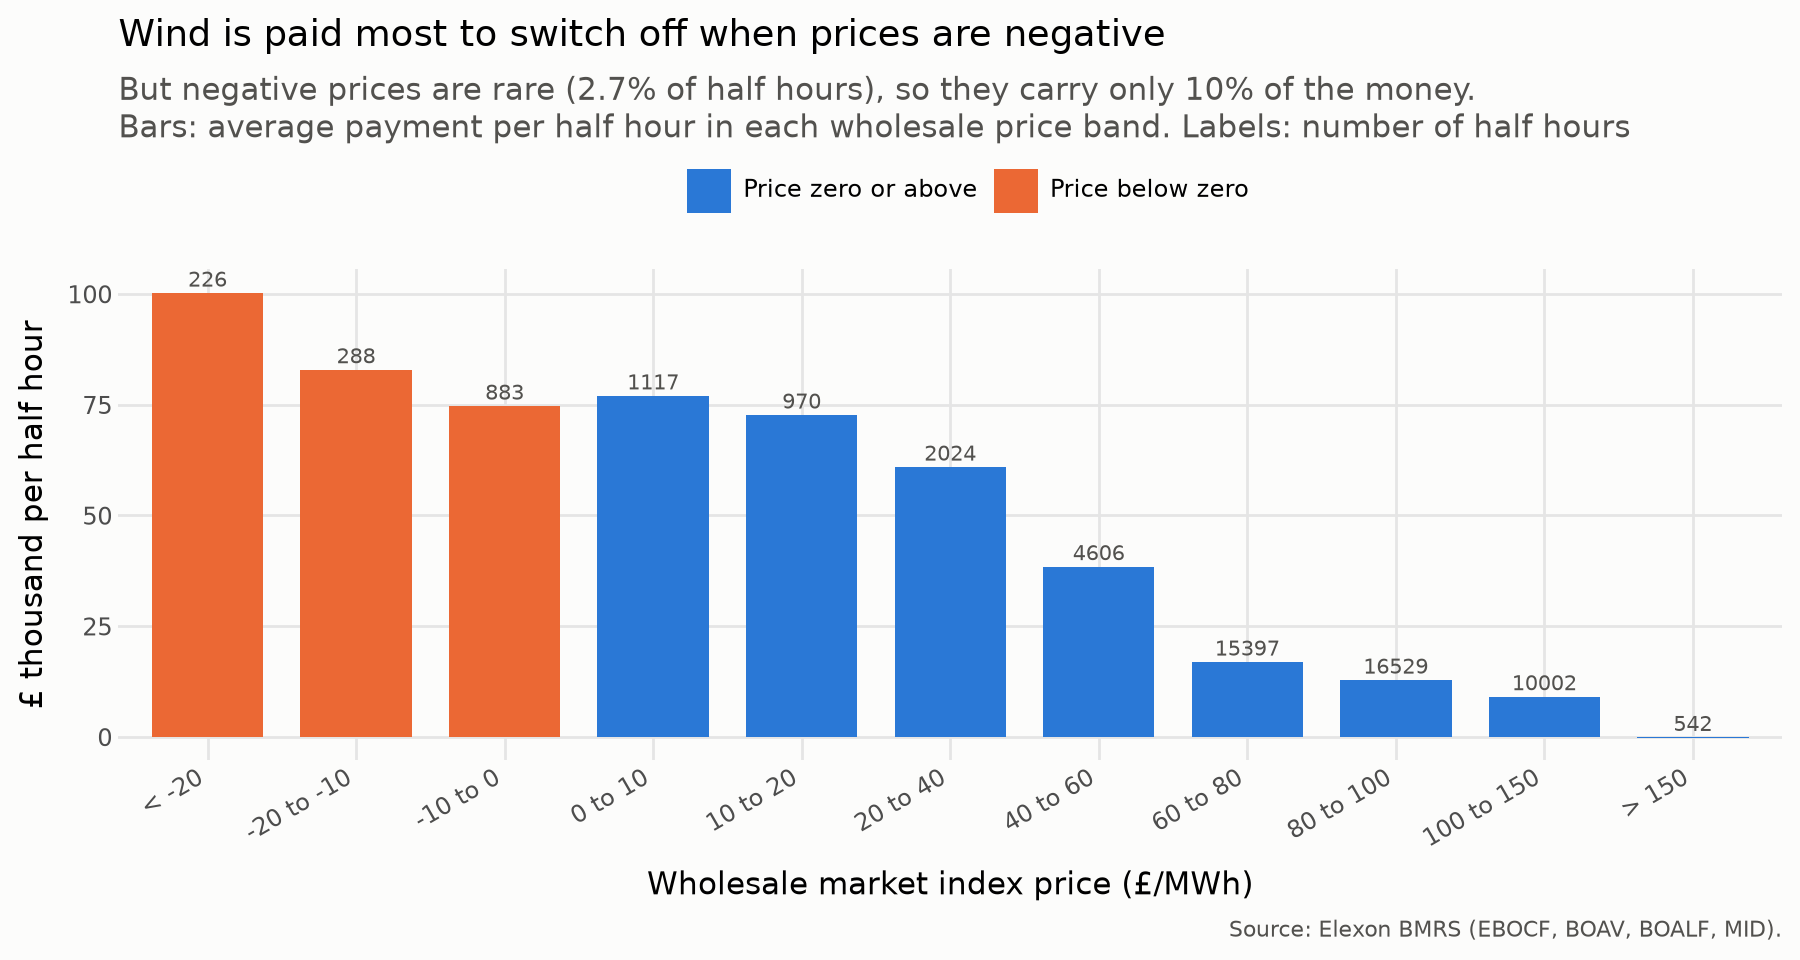

In [8]:
bands = [-np.inf, -20, -10, 0, 10, 20, 40, 60, 80, 100, 150, np.inf]
labels = ["< -20", "-20 to -10", "-10 to 0", "0 to 10", "10 to 20", "20 to 40", "40 to 60",
          "60 to 80", "80 to 100", "100 to 150", "> 150"]
priced = half.dropna(subset=["mid_price_gbp_mwh"]).copy()
priced["band"] = pd.cut(priced["mid_price_gbp_mwh"], bands, labels=labels, right=False)
by_band = priced.groupby("band", observed=False).agg(
    mean_cash=("wind_cash", "mean"), half_hours=("wind_cash", "size"),
    share_curtailing=("wind_cash", lambda s: (s > 0).mean())).reset_index()
by_band["negative"] = by_band["band"].astype(str).str.startswith(("<", "-"))
print(by_band.round(2).to_string(index=False))
corr_price = priced[["mid_price_gbp_mwh", "wind_cash"]].corr().iloc[0, 1]
negative_share_hh = (priced["mid_price_gbp_mwh"] < 0).mean()
negative_share_cash = priced.loc[priced["mid_price_gbp_mwh"] < 0, "wind_cash"].sum() / priced["wind_cash"].sum()
print(f"Negative-price half hours: {negative_share_hh:.1%} of all; they carry {negative_share_cash:.1%} of paid curtailment")

save(
    ggplot(by_band, aes("band", "mean_cash / 1e3", fill="negative"))
    + geom_col(width=0.75)
    + geom_text(aes(label="half_hours"), va="bottom", size=7.5, color="#52514e", nudge_y=0.4)
    + scale_fill_manual(values={True: "#eb6834", False: "#2a78d6"}, labels={True: "Price below zero", False: "Price zero or above"})
    + labs(title="Wind is paid most to switch off when prices are negative",
           subtitle=f"But negative prices are rare ({negative_share_hh:.1%} of half hours), so they carry only {negative_share_cash:.0%} of the money.\n"
                    "Bars: average payment per half hour in each wholesale price band. Labels: number of half hours",
           x="Wholesale market index price (£/MWh)", y="£ thousand per half hour", fill="", caption=ELEXON)
    + house_theme() + theme(axis_text_x=element_text(rotation=30, ha="right")),
    "06_price_vs_curtailment",
)

## 6. How concentrated is it?

### 6a. On which days

Five most expensive days (£m):
settlement_date  wind_cash
     2024-09-10        7.9
     2023-07-01        7.4
     2025-08-05        6.9
     2024-12-21        6.9
     2024-10-20        6.9


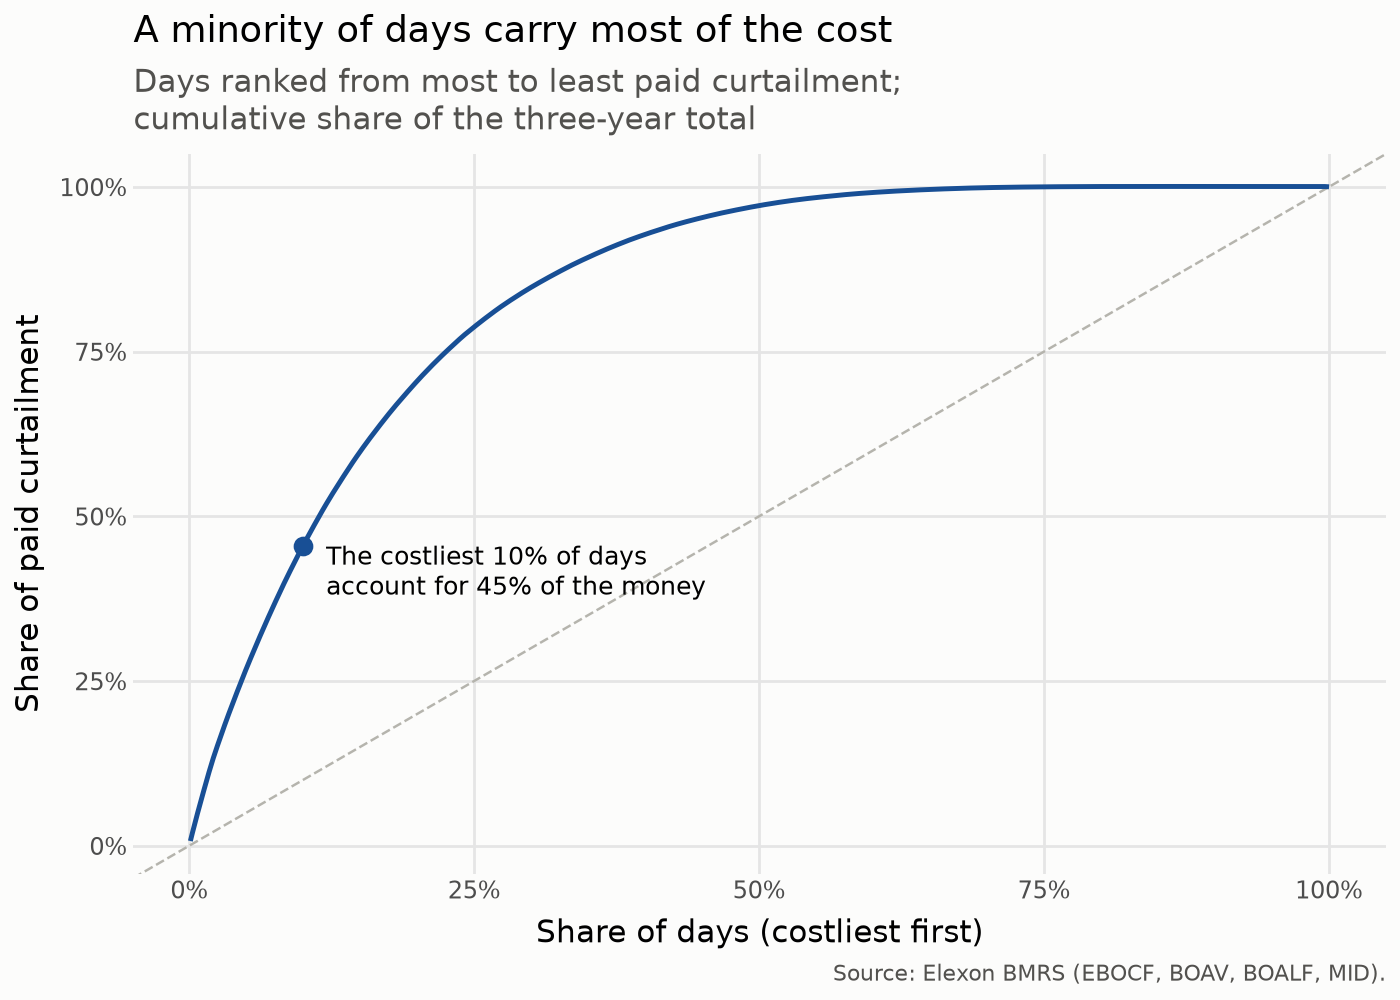

In [9]:
daily = half.groupby("settlement_date")["wind_cash"].sum().sort_values(ascending=False).reset_index()
daily["share_of_days"] = np.arange(1, len(daily) + 1) / len(daily)
daily["share_of_cost"] = daily["wind_cash"].cumsum() / daily["wind_cash"].sum()
top10 = daily.loc[daily["share_of_days"] <= 0.10, "share_of_cost"].max()
top_days = daily.head(5)[["settlement_date", "wind_cash"]].assign(wind_cash=lambda d: (d["wind_cash"] / 1e6).round(1))
print("Five most expensive days (£m):"); print(top_days.to_string(index=False))

save(
    ggplot(daily, aes("share_of_days", "share_of_cost"))
    + geom_abline(intercept=0, slope=1, color="#b5b4ad", linetype="dashed")
    + geom_line(color="#184f95", size=1)
    + annotate("point", x=0.10, y=top10, color="#184f95", size=3)
    + annotate("text", x=0.12, y=top10 - 0.04, ha="left", size=9,
               label=f"The costliest 10% of days\naccount for {top10:.0%} of the money")
    + scale_x_continuous(labels=lambda b: [f"{v:.0%}" for v in b])
    + scale_y_continuous(labels=lambda b: [f"{v:.0%}" for v in b])
    + labs(title="A minority of days carry most of the cost",
           subtitle="Days ranked from most to least paid curtailment;\ncumulative share of the three-year total",
           x="Share of days (costliest first)", y="Share of paid curtailment", caption=ELEXON)
    + house_theme(width=7, height=5),
    "07_concentration_days",
)

### 6b. Which wind farms

135 wind sites were paid; the top 15 took 61%


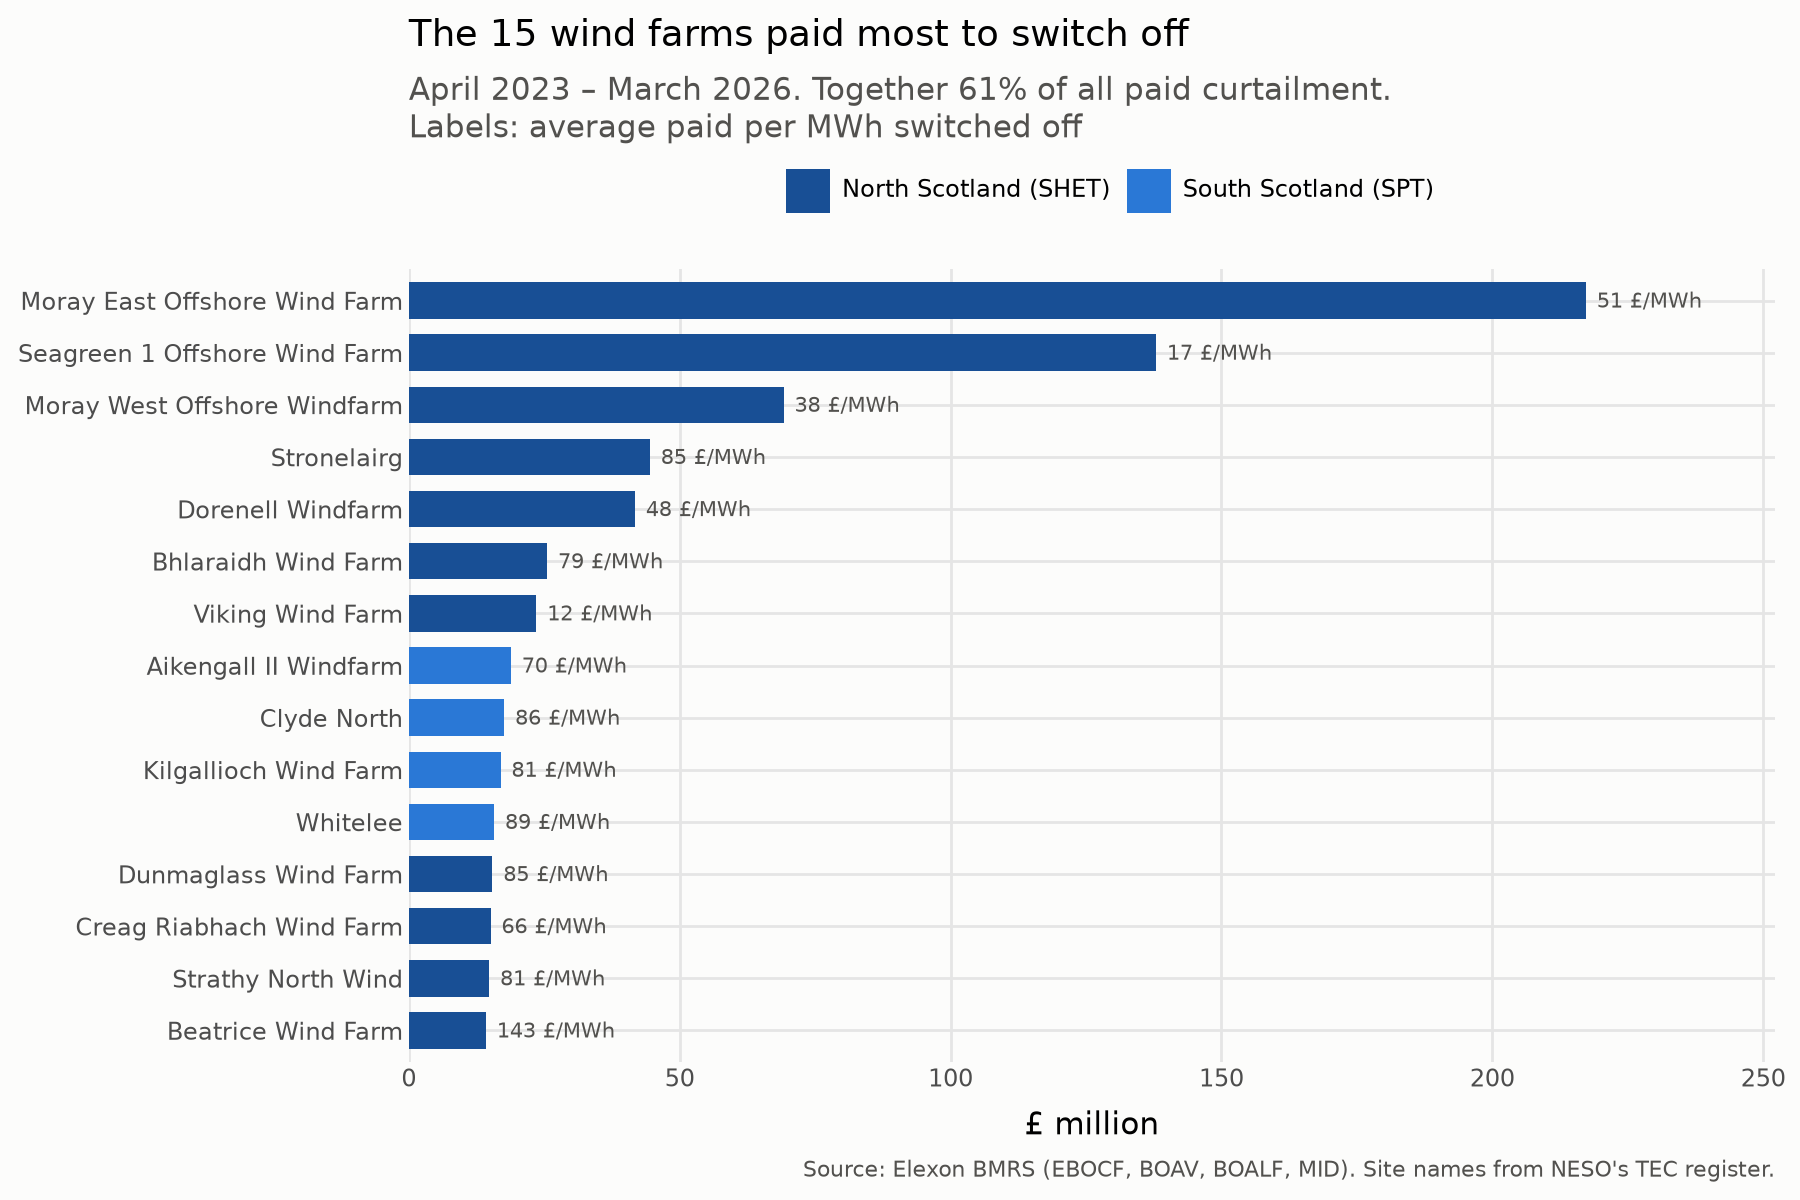

In [10]:
site_names = pd.read_csv(DATA / "wind_site_matches.csv").set_index("site")["tec_project"]
wind_paid = by_unit[(by_unit["side"] == "bid") & by_unit["host_to"].notna()].copy()
wind_paid["site_name"] = wind_paid["site"].map(site_names).fillna(wind_paid["name"])
sites = (wind_paid.groupby(["site_name", "host_to"], as_index=False)
         .agg(cash_gbp=("cash_gbp", "sum"), mwh=("volume_mwh", lambda v: -v.sum())))
sites["gbp_per_mwh"] = sites["cash_gbp"] / sites["mwh"]
sites = sites.sort_values("cash_gbp", ascending=False)
top15 = sites.head(15).copy()
top15_share = top15["cash_gbp"].sum() / sites["cash_gbp"].sum()
top15["region"] = top15["host_to"].map(REGIONS)
top15["site_name"] = pd.Categorical(top15["site_name"], categories=top15["site_name"][::-1])
print(f"{len(sites)} wind sites were paid; the top 15 took {top15_share:.0%}")

save(
    ggplot(top15, aes("site_name", "cash_gbp / 1e6", fill="region"))
    + geom_col(width=0.7)
    + geom_text(aes(label="gbp_per_mwh.round(0).astype(int).astype(str) + ' £/MWh'"), ha="left", nudge_y=2, size=7.5, color="#52514e")
    + coord_flip()
    + scale_fill_manual(values=REGION_COLOURS)
    + scale_y_continuous(expand=(0, 0, 0.15, 0))
    + labs(title="The 15 wind farms paid most to switch off",
           subtitle=f"April 2023 – March 2026. Together {top15_share:.0%} of all paid curtailment.\nLabels: average paid per MWh switched off",
           x="", y="£ million", fill="", caption=ELEXON + " Site names from NESO's TEC register.")
    + house_theme(height=6),
    "08_top_wind_farms",
)

## 7. Price paid per MWh switched off

C:\Users\alecm\OneDrive\Documents\Work\Internships\Finance\Projects\below-zero\.venv\Lib\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_point : Removed 23 rows containing missing values.
C:\Users\alecm\OneDrive\Documents\Work\Internships\Finance\Projects\below-zero\.venv\Lib\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_point : Removed 23 rows containing missing values.


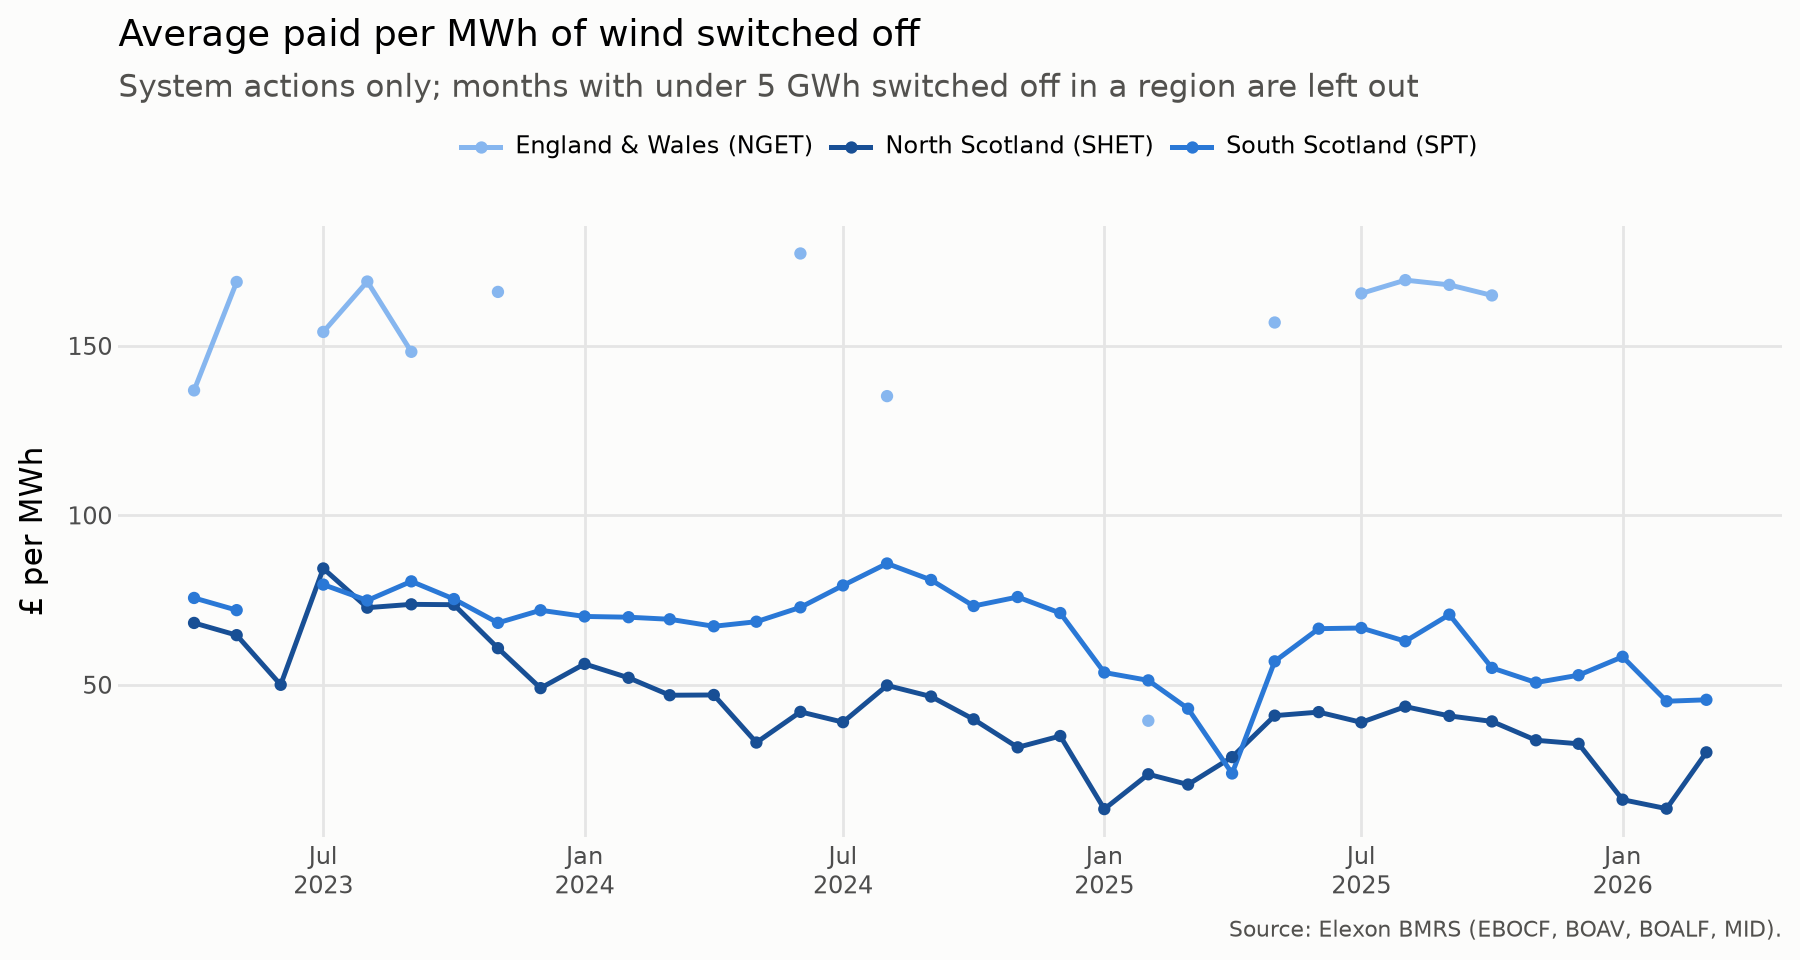

In [11]:
per_mwh = half.melt(id_vars="month", value_vars=[c for c in cash_cols + vol_cols if c.endswith("_system")])
per_mwh[["measure", "host_to"]] = per_mwh["variable"].str.extract(r"wind_bid_(cash_gbp|volume_mwh)_(\w+)_system")
per_mwh = per_mwh.pivot_table(index=["month", "host_to"], columns="measure", values="value", aggfunc="sum").reset_index()
per_mwh["gbp_per_mwh"] = per_mwh["cash_gbp"] / -per_mwh["volume_mwh"]
per_mwh["region"] = per_mwh["host_to"].map(REGIONS)
# Months with very little volume give noisy prices; drop below 5 GWh
per_mwh.loc[-per_mwh["volume_mwh"] < 5000, "gbp_per_mwh"] = np.nan
# A full month x region grid, so a left-out month breaks the line instead of being bridged
grid = pd.MultiIndex.from_product([sorted(half["month"].unique()), list(REGIONS)], names=["month", "host_to"])
per_mwh = per_mwh.set_index(["month", "host_to"]).reindex(grid).reset_index()
per_mwh["region"] = per_mwh["host_to"].map(REGIONS)

save(
    ggplot(per_mwh, aes("month", "gbp_per_mwh", color="region"))
    + geom_line(size=1) + geom_point(size=1.5)
    + scale_color_manual(values=REGION_COLOURS)
    + scale_x_datetime(date_labels="%b\n%Y", date_breaks="6 months")
    + labs(title="Average paid per MWh of wind switched off",
           subtitle="System actions only; months with under 5 GWh switched off in a region are left out",
           x="", y="£ per MWh", color="", caption=ELEXON)
    + house_theme(),
    "09_price_per_mwh",
)

## 8. The other side: who is paid to replace it

System-flagged offers (paid to increase output) to units that are not mapped wind, ranked by cash. This is not all replacement for curtailed wind: it also includes voltage and other system actions.

System-flagged offers to non-wind units: £1,778m; by fuel (£m): {'CCGT': 1676.0, 'BIOMASS': 67.0, 'COAL': 21.0, 'not set': 5.0, 'PS': 4.0, 'NPSHYD': 2.0, 'OTHER': 2.0, 'OCGT': 1.0}


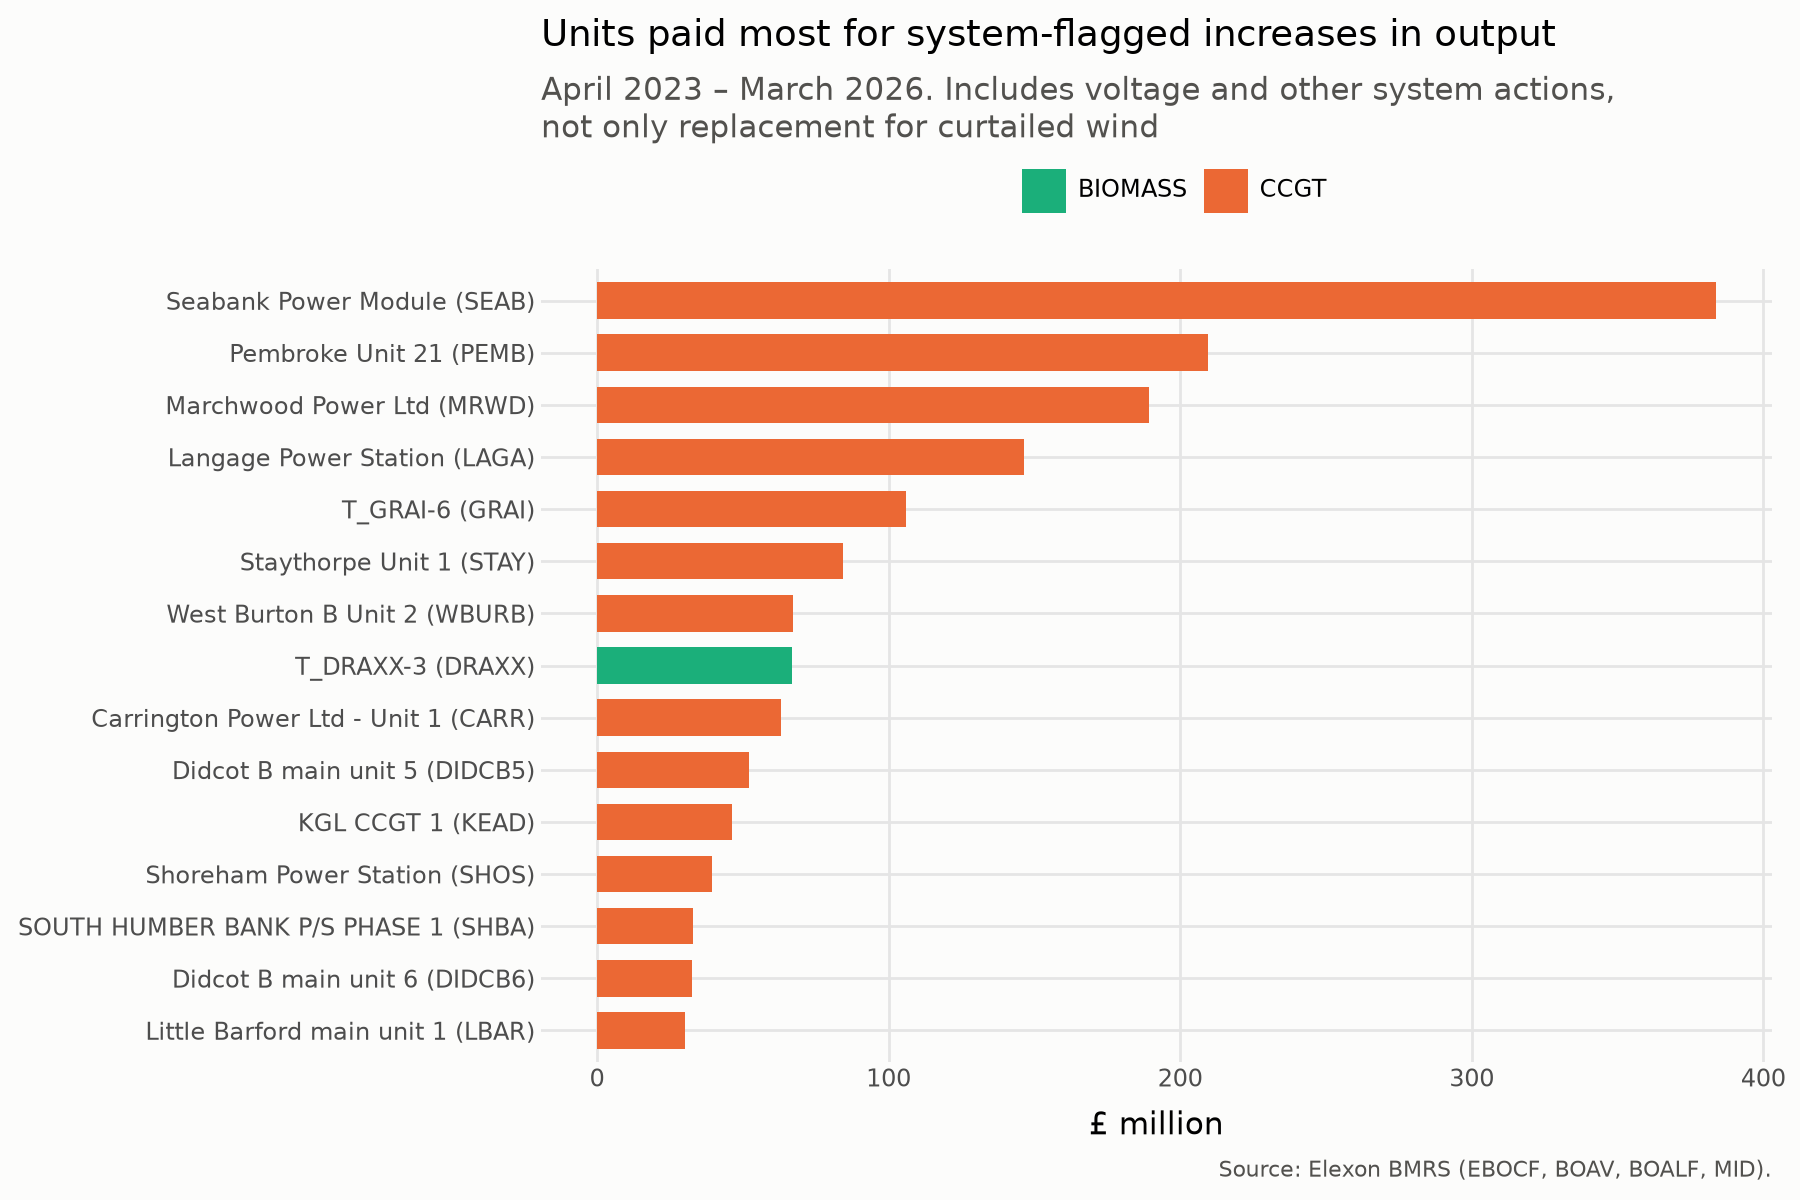

In [12]:
offers = by_unit[(by_unit["side"] == "offer") & (by_unit["action"] == "system") & by_unit["host_to"].isna()].copy()
offers["station"] = offers["ng_bm_unit"].fillna(offers["bm_unit"]).str.split("-").str[0]
offers["fuel_type"] = offers["fuel_type"].fillna("not set")
stations = (offers.groupby("station", as_index=False)
            .agg(cash_gbp=("cash_gbp", "sum"), mwh=("volume_mwh", "sum"),
                 name=("name", "first"), fuel=("fuel_type", lambda f: f.mode().iat[0])))
stations = stations.sort_values("cash_gbp", ascending=False)
top_st = stations.head(15).copy()
top_st["label"] = top_st["name"].fillna(top_st["station"]) + " (" + top_st["station"] + ")"
top_st["label"] = pd.Categorical(top_st["label"], categories=top_st["label"][::-1])
print(f"System-flagged offers to non-wind units: £{stations['cash_gbp'].sum() / 1e6:,.0f}m; "
      f"by fuel (£m): {(offers.groupby('fuel_type')['cash_gbp'].sum() / 1e6).round(0).sort_values(ascending=False).to_dict()}")

save(
    ggplot(top_st, aes("label", "cash_gbp / 1e6", fill="fuel"))
    + geom_col(width=0.7)
    + coord_flip()
    + scale_fill_manual(values={"CCGT": "#eb6834", "OCGT": "#eda100", "BIOMASS": "#1baf7a", "COAL": "#52514e",
                                "PS": "#6250d6", "NPSHYD": "#2a78d6", "OTHER": "#b5b4ad", "not set": "#e87ba4"})
    + labs(title="Units paid most for system-flagged increases in output",
           subtitle="April 2023 – March 2026. Includes voltage and other system actions,\nnot only replacement for curtailed wind",
           x="", y="£ million", fill="", caption=ELEXON)
    + house_theme(height=6),
    "10_top_replacement_units",
)